# 05 — Scheduled capacity from GTFS: does knowing how many buses run help?

**Question.** An overload happens when demand exceeds capacity, and so far the models only saw demand. Does adding **scheduled capacity** improve the predictions? Capacity here means how many buses Halifax Transit scheduled on each route, in each period, on each day.

Everything else is unchanged from rounds 2–3:
- same rows, same split (train 2022–2024 · validation 2025 · test 2026), same metrics and bootstrap CIs;
- settings and the final model are chosen on **2025 only**.

Code: `src/capacity.py` (features → `panel_capacity.parquet`) and `src/round4.py` (comparison).

**About the test set.** 2026 has now been looked at in rounds 2, 3 and 4. Each round-4 feature set was evaluated on 2026 **once** (`python src/round4.py --test`, timestamp below), and this notebook only reads the saved predictions. Repeated looks make 2026 less "unseen", which is one more reason to confirm the final model on a fresh period (Nov 2026 onward) before publishing.

**Data.** Halifax Transit GTFS schedules: **27 archived versions** (Aug 2021 – Nov 2026) from the [Transitland feed archive](https://www.transit.land/feeds/f-dxfy-halifaxtransit~hrm) (feed `f-dxfy-halifaxtransit~hrm`), downloaded through the Transitland API. Contains information licenced under the Open Government Licence — Halifax.
- **No look-ahead:** for each day we use the **latest schedule version fetched *before* that day**. Published schedules are known in advance.
- **One exception:** a single day, 2026-08-24, uses a version fetched on its own start date.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick
from sklearn.metrics import average_precision_score
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import round4 as R4
from capacity import CAP
warnings.simplefilter("ignore")
REP, FIG = ROOT / "reports", ROOT / "reports" / "figures"
BLUE, ORANGE, AQUA, YELLOW, PINK, GREEN, VIOLET, RED = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK2, MUTED, GRID, AXIS, SURF, GRAY = "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb", "#a3a29b"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110, "font.size": 10})
def save(fig, name): fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); print("saved", FIG / f"{name}.png")
pd.set_option("display.width", 200)
df = R4.load()
print(json.loads((REP / "r4_test_run.json").read_text()))

{'run_at': '2026-11-23T12:58:09', 'best_on_validation': 'LightGBM I_all_capacity', 'trained_on': '2022-2024', 'note': 'single evaluation of the round-4 (capacity) feature sets on 2026'}


## 1. The capacity features

| Feature | Definition (per route × day × period; trips counted by their first departure time) |
|---|---|
| `sched_trips` | scheduled trips starting in the period, both directions |
| `sched_trips_peakdir` | trips in the direction with more trips |
| `sched_trips_per_hour` | `sched_trips` ÷ period length |
| `load_per_trip` | **recent demand ÷ today's capacity**: average boardings over the previous 4 same weekdays ÷ `sched_trips` (expected riders per scheduled bus) |
| `peakdir_load_per_trip` | the same, for the busier direction |
| `sched_change_4w` | `sched_trips` ÷ the count 4 same-weekdays earlier (service added or cut?) |

GTFS does not say which buses are articulated (bigger), so capacity is counted in **trips**, not seats.

## 2. Halifax barely changed scheduled service on these routes

saved C:\Users\user\Desktop\ML project\reports\figures\20_r4_schedules_flat.png


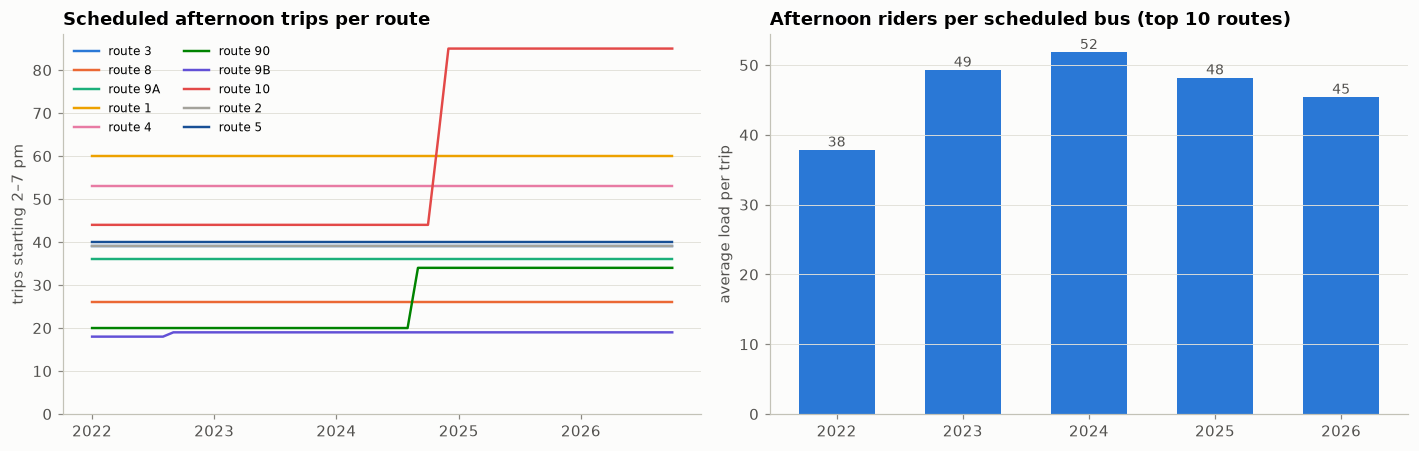

rows where scheduled trips changed vs 4 weeks earlier: 0.4%


In [2]:
pm = df[df.period == "PM"]
s = pm.groupby([pd.Grouper(key="date", freq="MS"), "route"], observed=True).sched_trips.median().unstack()
dem = pm.groupby(pd.Grouper(key="date", freq="MS")).boardings_mean4w.sum()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.2))
cols = [BLUE, ORANGE, AQUA, YELLOW, PINK, GREEN, VIOLET, RED, GRAY, "#184f95"]
for c, r in zip(cols, s.columns):
    a1.plot(s.index, s[r], color=c, lw=1.6, label=f"route {r}")
a1.set_title("Scheduled afternoon trips per route"); a1.set_ylabel("trips starting 2–7 pm"); a1.set_ylim(0)
a1.legend(ncol=2, fontsize=8, loc="upper left")
lpt = pm.groupby("year").load_per_trip.mean()
a2.bar(lpt.index.astype(str), lpt.values, width=0.6, color=BLUE)
for i, v in enumerate(lpt.values): a2.text(i, v, f"{v:.0f}", ha="center", va="bottom", fontsize=9, color=INK2)
a2.set_title("Afternoon riders per scheduled bus (top 10 routes)"); a2.set_ylabel("average load per trip")
fig.tight_layout(); save(fig, "20_r4_schedules_flat"); plt.show()
print("rows where scheduled trips changed vs 4 weeks earlier:", f"{(df.sched_change_4w.round(3) != 1).mean():.1%}")

**What this tells us**
- **Scheduled trips are almost constant:** only about 0.4% of rows show any change from 4 weeks earlier. The visible changes are route 90 (more trips in 2025) and route 10 (its 2024 split into 10A/B/C, counted together). Routes 2 and 3 both run 39 afternoon trips, so their lines overlap.
- **Riders per scheduled bus rose from 38 in 2022 to about 50 in 2023–2025, then eased to 45 in 2026** (matching 2026's lower overload rate). Demand grew while service stayed flat, which is a plausible structural reason why overloads became more common.
- **For prediction, though,** a number that hardly changes within a route and period adds little beyond knowing the route and period.

## 3. Raw signal (training years 2022–2024)

saved C:\Users\user\Desktop\ML project\reports\figures\21_r4_load_per_trip_signal.png


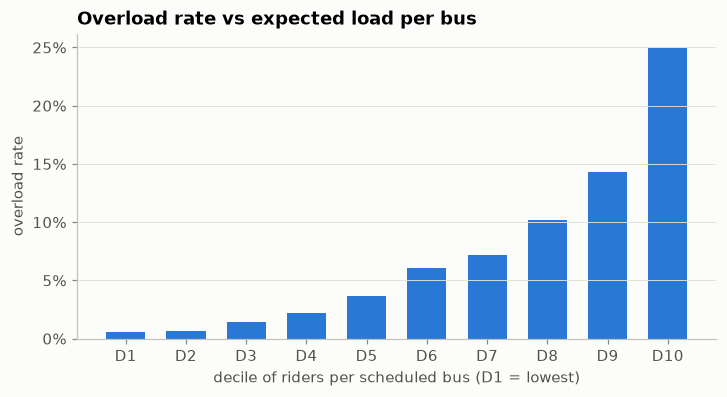

corr(load_per_trip, boardings_mean4w) = 0.68


In [3]:
t = df[df.split == "train"]
r = t.groupby(pd.qcut(t.load_per_trip, 10, labels=False), observed=True).y.mean()
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.bar([f"D{i+1}" for i in r.index], r.values, width=0.65, color=BLUE)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_ylabel("overload rate")
ax.set_xlabel("decile of riders per scheduled bus (D1 = lowest)"); ax.set_title("Overload rate vs expected load per bus")
save(fig, "21_r4_load_per_trip_signal"); plt.show()
print("corr(load_per_trip, boardings_mean4w) =", round(t[["load_per_trip", "boardings_mean4w"]].corr().iloc[0, 1], 2))

The raw pattern is strong (about 0.5% → 25%), but it mostly restates *busy route + busy period*. That is what the earlier features already capture, so the real test is whether it adds anything **on top**.

## 4. Validation 2025: choosing settings and the final model

In [4]:
val = pd.read_csv(REP / "r4_val_results.csv")
display(val[["model", "pr_auc", "roc_auc", "recall_top5", "recall_top10", "params"]].round(4))
display(pd.read_csv(REP / "r4_val_seed_stability.csv").round(4))
pd.read_csv(REP / "r4_val_capacity_gains.csv").pivot_table(index=["model", "vs"], columns="metric", values=["diff", "ci_low", "ci_high"]).round(3)

,model,pr_auc,roc_auc,recall_top5,recall_top10,params
0,Baseline: hist rate,0.3207,0.8225,0.2088,0.3882,NaN
1,Baseline: last week,0.1647,0.6215,0.1605,0.3179,NaN
2,LogReg A_time,0.3703,0.8413,0.2434,0.4250,"{""C"": 0.01, ""interact"": true}"
3,LightGBM A_time,0.3721,0.8481,0.2340,0.4155,"{""num_leaves"": 7, ""min_child_samples"": 20, ""n_..."
4,LogReg B_history,0.3923,0.8532,0.2497,0.4481,"{""C"": 1.0, ""interact"": false}"
5,LightGBM B_history,0.3924,0.8580,0.2602,0.4470,"{""num_leaves"": 7, ""min_child_samples"": 20, ""n_..."
6,LogReg F_all3_weather,0.3938,0.8553,0.2539,0.4439,"{""C"": 0.01, ""interact"": true}"
7,LightGBM F_all3_weather,0.3994,0.8595,0.2529,0.4565,"{""num_leaves"": 15, ""min_child_samples"": 100, ""..."
8,LogReg G_capacity,0.3757,0.8460,0.2371,0.4134,"{""C"": 0.1, ""interact"": false}"
9,LightGBM G_capacity,0.3737,0.8484,0.2308,0.4250,"{""num_leaves"": 7, ""min_child_samples"": 100, ""n..."


,feature_set,mean,sd
0,A_time,0.3710,0.0009
1,B_history,0.3916,0.0008
2,F_all3_weather,0.3956,0.0023
3,G_capacity,0.3722,0.0009
4,H_history_capacity,0.3965,0.0010
5,I_all_capacity,0.3973,0.0019


ci_high                              ci_low                                diff                             
metric                                               PR-AUC recall top 10% recall top 5% PR-AUC recall top 10% recall top 5% PR-AUC recall top 10% recall top 5%
model                       vs                                                                                                                                  
LightGBM G_capacity         LightGBM A_time           0.018          0.030         0.017 -0.015         -0.009        -0.021  0.002          0.010        -0.002
LightGBM H_history_capacity LightGBM B_history        0.014          0.026         0.008 -0.005         -0.005        -0.021  0.004          0.007        -0.005
LightGBM I_all_capacity     LightGBM F_all3_weather   0.008          0.022         0.017 -0.006         -0.008        -0.007  0.000          0.005         0.005
LogReg G_capacity           LogReg A_time             0.017          0.014         0.013 -0.005         -0.029        -0.020  0.005         -0.012        -0.006
LogReg H_history_capacity   LogReg B_history          0.009          0.016         0.016 -0.003         -0.008        -0.007  0.003          0.005         0.006
LogReg I_all_capacity       LogReg F_all3_weather     0.009          0.020         0.010 -0.002         -0.003        -0.010  0.004          0.010         0.001

**Selection rule (fixed before the test run):** the highest validation PR-AUC. It picks **LightGBM I (everything + capacity)** at 0.3999, only 0.0005 above round 3's final model F (0.3994). Within each pair, adding capacity changes validation PR-AUC by +0.000 to +0.005, and every interval includes zero.

## 5. Test 2026: single evaluation (read from saved predictions)

,model,pr_auc,roc_auc,recall_top5,incidents_top5,recall_top10
0,Baseline: hist rate,0.2487,0.8035,0.2058,0.2369,0.3826
1,Baseline: last week,0.1415,0.6148,0.1966,0.2114,0.3064
2,LogReg A_time,0.2828,0.8236,0.2530,0.3013,0.3796
3,LightGBM A_time,0.2919,0.8323,0.2424,0.2868,0.3933
4,LogReg B_history,0.3652,0.8507,0.3064,0.3730,0.4695
5,LightGBM B_history,0.3605,0.8528,0.2912,0.3512,0.4680
6,LogReg F_all3_weather,0.3654,0.8533,0.3003,0.3682,0.4695
7,LightGBM F_all3_weather,0.3698,0.8556,0.2957,0.3572,0.4695
8,LogReg G_capacity,0.2958,0.8241,0.2439,0.2807,0.4268
9,LightGBM G_capacity,0.3015,0.8328,0.2424,0.2843,0.4314


saved C:\Users\user\Desktop\ML project\reports\figures\22_r4_capacity_gains.png


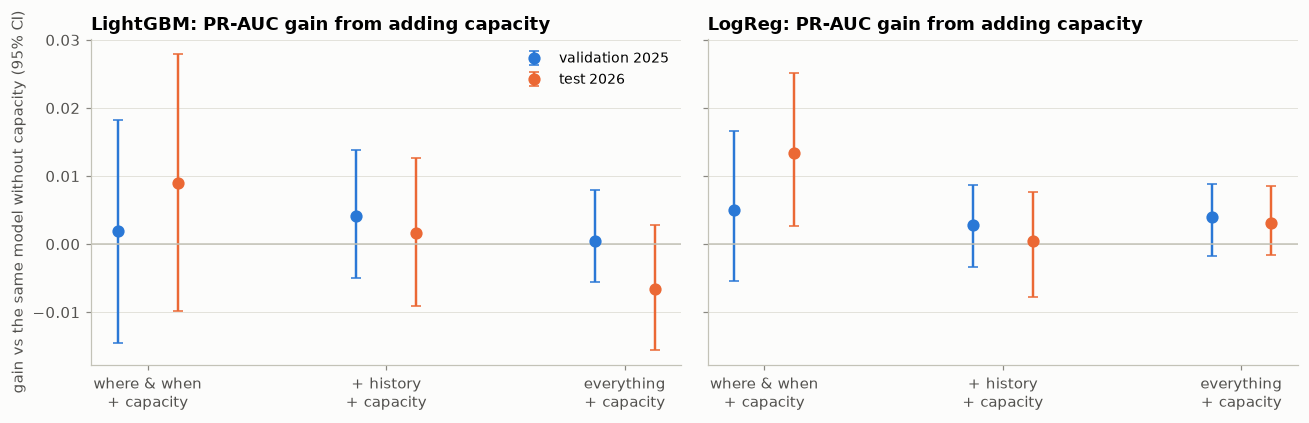

ci_high                              ci_low                                diff                             
metric                                               PR-AUC recall top 10% recall top 5% PR-AUC recall top 10% recall top 5% PR-AUC recall top 10% recall top 5%
model                       vs                                                                                                                                  
LightGBM G_capacity         LightGBM A_time           0.028          0.056         0.022 -0.010          0.006        -0.019  0.009          0.038         0.000
LightGBM H_history_capacity LightGBM B_history        0.013          0.020         0.021 -0.009         -0.014        -0.014  0.002          0.000         0.008
LightGBM I_all_capacity     LightGBM F_all3_weather   0.003          0.015         0.018 -0.016         -0.019        -0.012 -0.007          0.003         0.002
LogReg G_capacity           LogReg A_time             0.025          0.064         0.011  0.003          0.013        -0.029  0.013          0.047        -0.009
LogReg H_history_capacity   LogReg B_history          0.008          0.013         0.011 -0.008         -0.016        -0.016  0.000          0.000        -0.003
LogReg I_all_capacity       LogReg F_all3_weather     0.009          0.019         0.015 -0.002         -0.008        -0.009  0.003          0.002         0.002

In [5]:
test = pd.read_csv(REP / "r4_test_results.csv")
display(test[["model", "pr_auc", "roc_auc", "recall_top5", "incidents_top5", "recall_top10"]].round(4))
gv = pd.read_csv(REP / "r4_val_capacity_gains.csv").assign(split="validation 2025")
gt = pd.read_csv(REP / "r4_test_capacity_gains.csv").assign(split="test 2026")
g = pd.concat([gv, gt]); g = g[g.metric == "PR-AUC"]
labels = {"G_capacity": "where & when\n+ capacity", "H_history_capacity": "+ history\n+ capacity", "I_all_capacity": "everything\n+ capacity"}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, fam in zip(axes, ["LightGBM", "LogReg"]):
    for j, (split, col) in enumerate([("validation 2025", BLUE), ("test 2026", ORANGE)]):
        s = g[(g.split == split) & g.model.str.startswith(fam)].copy()
        s["fs"] = s.model.str.split(" ", n=1).str[1]; s = s.set_index("fs").reindex(list(labels))
        x = np.arange(3) + (j - 0.5) * 0.25
        ax.errorbar(x, s["diff"], yerr=[s["diff"] - s.ci_low, s.ci_high - s["diff"]], fmt="o", ms=7, color=col,
                    ecolor=col, elinewidth=1.6, capsize=3, label=split)
    ax.axhline(0, color=AXIS, lw=1); ax.set_xticks(range(3), list(labels.values())); ax.set_title(f"{fam}: PR-AUC gain from adding capacity")
axes[0].set_ylabel("gain vs the same model without capacity (95% CI)"); axes[0].legend(fontsize=9, loc="upper right")
fig.tight_layout(); save(fig, "22_r4_capacity_gains"); plt.show()
gt.pivot_table(index=["model", "vs"], columns="metric", values=["diff", "ci_low", "ci_high"]).round(3)

In [6]:
pd.read_csv(REP / "r4_test_gains_vs_baseline.csv").round(4)

,model,vs,metric,diff,ci_low,ci_high,p_le_0
0,LightGBM I_all_capacity,Baseline: hist rate,PR-AUC,0.1147,0.0866,0.1469,0.0
1,LightGBM I_all_capacity,Baseline: hist rate,recall top 5%,0.0899,0.0608,0.1295,0.0
2,LightGBM I_all_capacity,Baseline: hist rate,recall top 10%,0.0899,0.0527,0.1207,0.0


## 6. Summary (round 4, 2026-11-23)

**Does scheduled capacity help?** **No, not once recent overload history is in the model.**

| PR-AUC (LightGBM) | Without capacity | With capacity | Gain on 2026 [95% CI] |
|---|---|---|---|
| Where & when | 0.292 | 0.302 | +0.009 [−0.010, +0.028] |
| + overload history | 0.361 | 0.362 | +0.002 [−0.009, +0.013] |
| Everything | 0.370 | 0.363 | −0.007 [−0.016, +0.003] |

- **Without history,** capacity helps slightly. For logistic regression the gain is +0.013, with an interval just above zero, probably from the few real service changes (route 90 in 2025, the route 10 split).
- **With history,** the gain disappears: a route-period that keeps overloading already tells the model that demand exceeds capacity there.
- **Why so little?** Scheduled service on the top 10 routes barely changed from 2022 to 2026: only 0.4% of rows show a change. Capacity is therefore nearly identical to "which route and period", which the model already knows.

**Final model.**
- The pre-set validation rule picked **LightGBM I** (everything + capacity). It scores **PR-AUC 0.363** on 2026, +0.115 over the historical-rate rule (CI +0.087 to +0.147).
- Round 3's model F scored 0.370. The two are statistically the same (difference −0.007, CI −0.016 to +0.003).
- We report I because it was the pre-registered choice; switching to F after seeing the test would be test-set selection. The simpler history-only model (0.361) remains a good practical choice.

**An explanatory finding.** Riders per scheduled bus rose from 2022 to 2023–2025 while scheduled trips stayed flat. That supports the idea that overloads rose because demand grew into unchanged service. It explains the trend, even though it doesn't improve day-to-day prediction.

**Caveats**
- Trips are not seats: GTFS does not say which buses are articulated.
- Schedules are not what actually ran: cancelled or late trips are not visible.
- A fresh test period (Nov 2026 onward) is still needed before publishing.